# Author's Hand — Autonomous AI Research Agent that Summarises Research Papers
### …and a research workspace that turns selected papers into every section of your own paper
### Final Capstone Project · Option 5: *Autonomous AI Research Agent*

**Stack:** Python · LangChain (chat-model + tool layer) · Retrieval-Augmented Generation · scikit-learn · NetworkX · Streamlit · FastAPI
**Data sources:** ORCID · OpenAlex · Semantic Scholar · arXiv · Crossref · Unpaywall · ResearchGate (profile link + export)

| Notebook section | What it covers |
|---|---|
| 1 | Problem statement, objectives and what makes Author's Hand different |
| 2 | Setup and architecture |
| 3 – 10 | Step-by-step implementation (identity linking → profile intelligence → ingestion → summarisation → grounding → RAG → autonomous agent → literature review) |
| Part B | Research workspace: projects & folders, auto-refresh, full citations in all styles, Writing Studio (intro → hypotheses → future study), cheatsheets, journal quality check, Tool Hub, citation map |
| Part C | Version 3: sign-in & accounts, evidence tracing (passage · page · DOI · support), labels (extracted / AI-generated / candidate), corrections & field-specific terms, systematic review with PRISMA, Google Scholar metrics |
| 11 | Testing and evaluation (synthetic benchmark **and** the real-paper protocol with failure cases) |
| 12 | Final results |
| 13 | Live mode (internet + LLM) and conclusion |

> **Course link (IIT Guwahati E&ICT Academy — Generative AI).** The project applies the course modules directly: LLM prompting and structured output (summaries, writing studio), LangChain chat-model and tool abstractions (agent), embeddings/TF-IDF retrieval and RAG (paper chat, grounding), autonomous agents with planning and tool use (Research Agent), evaluation of generative output (ROUGE, baselines, faithfulness, human ratings), and deployment (Streamlit, FastAPI, Docker, desktop).
>
> **Personal contribution (to be completed by the student):** _describe here what you designed, decided, tested and wrote yourself — e.g. choice of problem, feature requirements, testing on your own papers, interpretation of results._ **AI-assistance disclosure:** parts of the code and text were drafted with an AI assistant and reviewed, tested and edited by the student.

> **Runs anywhere.** Every cell below runs **offline with no API key** using the built-in local engine and a bundled *synthetic* demo corpus. Set `LIVE = True` (section 13) to use the real scholarly APIs and any LLM provider.

## 1. Problem statement

Researchers — especially faculty who teach, mentor and publish at the same time — face three linked problems:

1. **Volume.** Several million scholarly articles appear each year. Reading enough of them to stay current, write a literature review or referee a paper takes hours per paper.
2. **Trust.** Generic AI summarisers are fluent but *hallucinate* numbers and claims, and give no way to check a sentence against the paper.
3. **Context-blindness.** Existing tools summarise a paper the same way for everyone. They do not know *who you are*, what you have already published, which themes you are building, or where your profile is weak — even though this information is openly available through your **ORCID** record and **ResearchGate** profile.

**Objective.** Build an autonomous research agent that, from a natural-language goal, plans and executes the full research workflow — *find → read → summarise → verify → relate to my work → synthesise* — anchored to the researcher's own ORCID / ResearchGate identity, with every summary claim traced to evidence in the source paper.

### What makes Author's Hand different from tools in the market

| Capability | Typical paper summarisers / AI search tools | **Author's Hand** |
|---|---|---|
| Structured summary (problem, method, data, findings, limitations, future work) | Partial | ✔ 9-field schema, 3 personas |
| Sentence-level evidence trail + faithfulness score | Rare | ✔ every claim linked to a source sentence |
| Self-reflection (re-summarise when evidence support is weak) | No | ✔ quality gate + strict retry |
| Linked to **your ORCID** and **ResearchGate** | No | ✔ unified, de-duplicated publication profile |
| "How does this paper relate to *my* work?" | No | ✔ relevance score + your closest papers |
| Research-theme momentum, gap opportunities, next-paper ideas | No | ✔ from your own record |
| Profile-health audit (discoverability fixes) | No | ✔ 8 checks with step-by-step fixes |
| Journal-fit suggestions | Separate tools | ✔ built in |
| Works with **no paid key**, offline, or with any LLM | Usually paid | ✔ local engine · Groq/Gemini free tiers · Ollama · Claude · OpenAI |
| Open APIs + REST endpoint for institutional portals | Closed | ✔ FastAPI |

## 2. Setup

In [1]:
# Install once (uncomment when running on a fresh machine / Colab)
# !pip install -r requirements.txt

import sys, warnings, json, time
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd()))

import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)

import authorshand as sp
from authorshand import (LLM, Settings, PaperSummarizer, PaperIndex, ResearcherProfile,
                          ResearchAgent, LiteratureReviewer, demo, evaluation, exporters, connectors)
llm = LLM("auto")          # picks a provider from env keys; falls back to the free local engine
print("Author's Hand", sp.__version__, "| reasoning engine:", llm.label)

Author's Hand 1.0.0 | reasoning engine: Local extractive engine (no LLM)


### Architecture
![architecture](docs/architecture_diagram.png)

The system has four layers: **presentation** (Streamlit app, FastAPI, this notebook), the **core package** (`authorshand/`), **open scholarly sources**, and **pluggable reasoning engines** behind one LangChain chat-model interface. The `ResearchAgent` sits on top and orchestrates the tools.

![workflow](docs/workflow_diagram.png)

## 3. Step 1 — Linking the research identity (ORCID + ResearchGate)

ORCID iDs carry an **ISO 7064 MOD 11-2 checksum**. Validating it locally avoids wasted API calls and catches typos immediately.

In [2]:
for oid in ["0000-0002-1825-0097",   # ORCID's official example iD (Josiah Carberry)
            "0000-0002-1825-0098",   # one digit changed
            demo.DEMO_ORCID]:        # synthetic demo iD used offline
    print(f"{oid}  valid={connectors.valid_orcid(oid)}")
print(connectors.extract_orcid("Profile: https://orcid.org/0000-0002-1825-0097"))

0000-0002-1825-0097  valid=True
0000-0002-1825-0098  valid=False
0000-0000-0000-0001  valid=True
0000-0002-1825-0097


**ResearchGate has no public API, and scraping it breaches its Terms of Service.** Author's Hand therefore links ResearchGate in two compliant ways:
1. the profile URL — detected automatically when the researcher lists it on ORCID (*Websites & social links*), or typed by the user;
2. the researcher's **own BibTeX/RIS export** from ResearchGate, which is parsed and merged.

In [3]:
rg_bib = demo.researchgate_export()
rg_works = connectors.ResearchGateLinker.parse_bibtex(rg_bib)
print(connectors.ResearchGateLinker.valid_profile_url("https://www.researchgate.net/profile/A-Demo"))
pd.DataFrame(rg_works)[["title", "authors", "year", "venue", "source"]]

True


,title,authors,year,venue,source
0,Large Language Models in Management Education: Opportunities and Risks,[A. Demo],2023,The International Journal of Management Education,ResearchGate
1,Chatbots for HR Helpdesks: Lessons from a Pilot Deployment,"[A. Demo, K. Rao]",2022,Proceedings of the Indian Academy of Management Conference,ResearchGate
2,Text Mining Employee Exit Interviews for Retention Insights,"[A. Demo, S. Iyer]",2021,Management Research Review,ResearchGate


Works from ORCID, OpenAlex and ResearchGate are merged: exact DOI match first, then fuzzy title match (≥ 0.92 similarity). Provenance is kept.

In [4]:
profile = ResearcherProfile.from_dict(demo.load_profile_dict())     # offline stand-in for from_orcid(...)
before = len(profile.works)
added = profile.add_researchgate_export(rg_bib)
profile.researchgate = "https://www.researchgate.net/profile/A-Demo"
print(f"ORCID+OpenAlex works: {before} | ResearchGate export: {len(rg_works)} | newly added after de-dup: {added} | total: {len(profile.works)}")

ORCID+OpenAlex works: 15 | ResearchGate export: 3 | newly added after de-dup: 2 | total: 17


## 4. Step 2 — Researcher intelligence

In [5]:
m = profile.metrics(); pd.Series(m).to_frame("value")

,value
works,17.00
citations,376.00
h_index,10.00
i10_index,10.00
first_year,2017.00
last_year,2026.00
open_access_share,0.47
with_doi_share,0.76


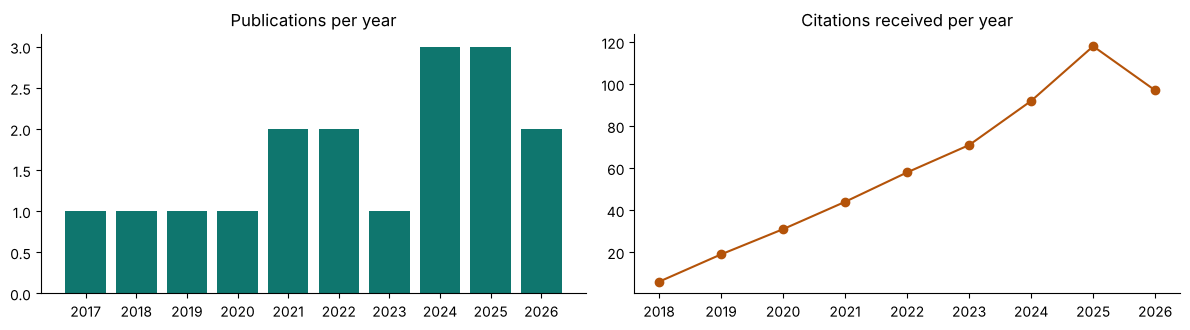

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
oby, cby = profile.output_by_year(), profile.citations_by_year()
ax[0].bar([str(y) for y in oby], list(oby.values()), color="#0f766e"); ax[0].set_title("Publications per year")
ax[1].plot([str(y) for y in cby], list(cby.values()), marker="o", color="#b45309"); ax[1].set_title("Citations received per year")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Research themes** are found by clustering TF-IDF vectors of titles and abstracts (K-Means). *Momentum* is the share of a theme's papers published in the last three years.

In [7]:
pd.DataFrame(profile.themes())[['theme', 'works', 'momentum', 'recent_share', 'citations']]

,theme,works,momentum,recent_share,citations
0,"ai, hr, generative",6,rising,0.67,85
1,"models, learning, prediction",4,fading,0.25,129
2,"gradient, boosting, retention",3,steady,0.33,71
3,"credit, thin, data",2,rising,1.00,40
4,"analytics, adoption, people",2,fading,0.00,51


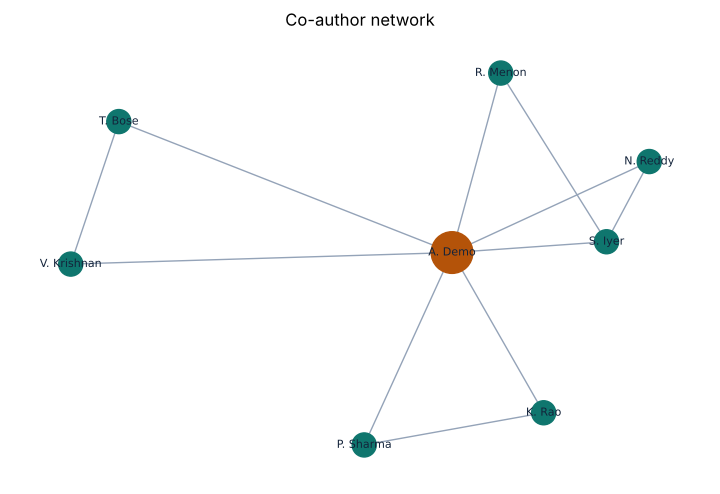

Top co-authors: [('S. Iyer', 5), ('N. Reddy', 4), ('K. Rao', 3), ('R. Menon', 2), ('P. Sharma', 2)]


In [8]:
import networkx as nx
g = profile.coauthor_graph()
plt.figure(figsize=(7, 4.5)); pos = nx.spring_layout(g, seed=7, k=0.9)
nx.draw(g, pos, with_labels=True, font_size=8, node_color=["#b45309" if g.nodes[n].get("kind")=="self" else "#0f766e" for n in g],
        node_size=[900 if g.nodes[n].get("kind")=="self" else 300 for n in g], edge_color="#94a3b8", font_color="#13233a")
plt.title("Co-author network"); plt.show()
print("Top co-authors:", profile.coauthors(5))

**Profile-health audit** — how discoverable is this researcher, and exactly what to fix:

In [9]:
h = profile.health_audit()
print("Profile health:", h["score"], "/ 100")
display(pd.DataFrame(h["checks"]))
for f in h["fixes"]: print("FIX →", f)

Profile health: 75 / 100


,check,passed
0,ORCID biography present,True
1,ORCID keywords present,True
2,Employment listed on ORCID,True
3,ResearchGate profile linked,True
4,≥ 80% of works carry a DOI,False
5,≥ 50% of works open access,False
6,Published in the last 2 years,True
7,Works abstract available (≥ 50%),True


FIX → Attach DOIs to works (ORCID → Works → Add → Search & link: Crossref).
FIX → Deposit accepted manuscripts in a repository/Zenodo to raise visibility.


**Gap opportunities** — pairs of the researcher's own themes that no paper has combined yet (a personalised, defensible source of new ideas), plus journal fit for a new manuscript:

In [10]:
display(pd.DataFrame(profile.gap_opportunities()))
manuscript = "LLM copilots and over-reliance of loan officers on incorrect AI credit recommendations"
pd.DataFrame(profile.recommend_venues(manuscript))

,theme_a,theme_b,papers_bridging,idea
0,"ai, hr, generative","models, learning, prediction",0,"Apply your work on “ai, hr, generative” to the problem space of “models, learning, prediction”."
1,"ai, hr, generative","gradient, boosting, retention",0,"Apply your work on “ai, hr, generative” to the problem space of “gradient, boosting, retention”."
2,"models, learning, prediction","gradient, boosting, retention",0,"Apply your work on “models, learning, prediction” to the problem space of “gradient, boosting, retention”."


,venue,fit,you_published_here
0,Decision Support Systems,0.402,1
1,Information Systems Research,0.108,1
2,Expert Systems with Applications,0.038,1
3,Personnel Review,0.035,2
4,Finance Research Letters,0.035,1


## 5. Step 3 — Paper ingestion (PDF → text → sections)
The demo corpus contains **5 synthetic papers** written for this project (clearly marked as not real publications) with hand-written reference summaries and 10 question–answer pairs for evaluation. One of them is also provided as a PDF.

In [11]:
corpus = demo.load_corpus()
pd.DataFrame(corpus["papers"])[["title", "authors", "year", "venue"]]

,title,authors,year,venue
0,Predicting Voluntary Employee Attrition with Explainable Gradient Boosting: Evidence from Indian IT Services,"[R. Menon, S. Iyer, A. Demo]",2025,Journal of Business Research
1,Generative AI Copilots and Analyst Productivity in Retail Banking: A Field Experiment,"[K. Rao, A. Demo, P. Sharma]",2026,Information Systems Research
2,Retrieval-Augmented Generation for Faithful Summarisation of Scientific Literature,"[L. Fernandes, M. Gupta]",2025,Information Processing & Management
3,Learning Analytics for Early Identification of At-Risk Postgraduate Management Students,"[N. Reddy, A. Demo]",2024,Computers & Education
4,Explainable Credit Scoring for Thin-File Borrowers Using Alternative Data,"[V. Krishnan, A. Demo, T. Bose]",2024,Finance Research Letters


In [12]:
from authorshand.pdf_reader import split_sections, guess_title
pdf_text = sp.read_pdf("demo_data/sample_paper_attrition.pdf")
sections = split_sections(pdf_text)
print("Title:", guess_title(pdf_text))
pd.DataFrame([(k, len(v.split()), v[:90] + "…") for k, v in sections.items()], columns=["section", "words", "starts with"])

Title: Predicting Voluntary Employee Attrition with Explainable Gradient Boosting: Evidence from Indian IT Services


,section,words,starts with
0,front_matter,32,Predicting Voluntary Employee Attrition with Explainable Gradient Boosting: Evidence from …
1,abstract,101,Voluntary attrition costs Indian IT services firms an estimated 1.5 to 2 times an employee…
2,introduction,94,"Attrition in Indian IT services rose sharply after 2021, with annual rates above 20 percen…"
3,literature,42,Prior work has used logistic regression and decision trees to model turnover intention. Re…
4,methodology,59,We frame attrition as a binary classification problem with a six-month prediction horizon.…
5,data,48,"The dataset contains 18,420 employee records collected between 2019 and 2023 from three IT…"
6,results,95,"XGBoost outperformed the other models with an AUC of 0.89, precision of 0.72 and recall of…"
7,discussion,37,The findings indicate that career progression and managerial stability matter more than co…
8,limitations,27,"The data come from only three firms in one industry, which limits generalisability. The mo…"
9,future_work,29,"Future research should test the model in other sectors, incorporate engagement survey text…"


## 6. Step 4 — Structured, evidence-grounded summarisation

Two engines share one output schema of **9 fields**: TL;DR, problem, objectives, methodology, data, key findings, contributions, limitations, future work.

* **LLM engine** (when a key is set): section-wise *map* → JSON-schema *reduce* → **self-verification** pass that deletes unsupported statements.
* **Local engine** (no key): each field is routed to the right sections, sentences containing field-specific cue words are ranked with **TextRank** (PageRank on a TF-IDF cosine graph), near-duplicates are removed (MMR-style), and limitations are **never invented** — only taken from what the paper states.

In [13]:
summarizer = PaperSummarizer(llm)
s = summarizer.summarize(pdf_text, persona="researcher")
print("TL;DR:", s["fields"]["tldr"], "\n")
for k, v in s["fields"].items():
    if k != "tldr": print(f"■ {k.upper()}"); [print("   •", x) for x in v]
print(f"\nfaithfulness={s['faithfulness']}  compression={s['compression']:.0%}  keywords={s['keywords']}  engine={s['engine']}")

TL;DR: Using HR records of 18,420 employees from three mid-sized IT firms, we compare logistic regression, random forest and XGBoost. 

■ PROBLEM
   • However, most predictive attrition studies rely on the public IBM HR dataset, which is synthetic and small.
   • Little is known about how well attrition models generalise to real Indian workforce data.
■ OBJECTIVES
   • This study addresses both gaps.
   • Our objective is to build an accurate and explainable early-warning model and to examine which organisational drivers matter most.
■ METHODOLOGY
   • Three models were trained: logistic regression, random forest and XGBoost.
   • Voluntary attrition costs Indian IT services firms an estimated 1.5 to 2 times an employee's annual salary per exit.
■ DATA
   • The dataset contains 18,420 employee records collected between 2019 and 2023 from three IT services firms in Bengaluru, Hyderabad and Pune.
   • The voluntary attrition rate in the sample is 17.6 percent.
■ KEY_FINDINGS
   • XGBoost

## 7. Step 5 — Evidence grounding & personalisation
Every claim is linked to its best-supporting source sentence (TF-IDF cosine). The mean support is the **faithfulness score** the agent uses as its quality gate.

In [14]:
pd.DataFrame(s['evidence'])[['field', 'support', 'section', 'claim']].head(10)

,field,support,section,claim
0,tldr,1.0,abstract,"Using HR records of 18,420 employees from three mid-sized IT firms, we compare logistic regression, random forest an..."
1,problem,1.0,introduction,"However, most predictive attrition studies rely on the public IBM HR dataset, which is synthetic and small."
2,problem,1.0,introduction,Little is known about how well attrition models generalise to real Indian workforce data.
3,objectives,1.0,introduction,This study addresses both gaps.
4,objectives,1.0,introduction,Our objective is to build an accurate and explainable early-warning model and to examine which organisational driver...
5,methodology,1.0,methodology,"Three models were trained: logistic regression, random forest and XGBoost."
6,methodology,1.0,abstract,Voluntary attrition costs Indian IT services firms an estimated 1.5 to 2 times an employee's annual salary per exit.
7,data,1.0,data,"The dataset contains 18,420 employee records collected between 2019 and 2023 from three IT services firms in Bengalu..."
8,data,1.0,data,The voluntary attrition rate in the sample is 17.6 percent.
9,key_findings,1.0,results,"XGBoost outperformed the other models with an AUC of 0.89, precision of 0.72 and recall of 0.81."


In [15]:
rel = PaperSummarizer.relevance_to_profile(s, profile.works)
print("Relevance of this paper to the researcher's own work:", rel["score"])
pd.DataFrame(rel["related_own_works"])

Relevance of this paper to the researcher's own work: 0.15


,title,year,similarity
0,Fairness Audits of Attrition Prediction Models,2022,0.060
1,Learning Analytics for Early Identification of At-Risk Postgraduate Management Students,2024,0.054
2,People Analytics Maturity in Indian Service Firms,2020,0.043


In [16]:
print(exporters.summary_markdown(s)[:1200])

# Predicting Voluntary Employee Attrition with Explainable Gradient Boosting: Evidence from Indian IT Services

*Engine: local · Faithfulness: 1.00 · Compression: 51.2% · Keywords: attrition, voluntary, model, explainable, indian, services, hr, firms*

## TL;DR
Using HR records of 18,420 employees from three mid-sized IT firms, we compare logistic regression, random forest and XGBoost.

## Research problem
- However, most predictive attrition studies rely on the public IBM HR dataset, which is synthetic and small.
- Little is known about how well attrition models generalise to real Indian workforce data.

## Objectives
- This study addresses both gaps.
- Our objective is to build an accurate and explainable early-warning model and to examine which organisational drivers matter most.

## Methodology
- Three models were trained: logistic regression, random forest and XGBoost.
- Voluntary attrition costs Indian IT services firms an estimated 1.5 to 2 times an employee's annual salary per 

## 8. Step 6 — Chat with papers (RAG)
Papers are split into sentence-aligned chunks (≈900 chars, 150-char overlap) labelled with their section. Retrieval fuses lexical TF-IDF with dense `all-MiniLM-L6-v2` embeddings (when `sentence-transformers` is installed) using **Reciprocal Rank Fusion**. Answers cite the chunks used as **[S1], [S2]…**; with an LLM they are generated from those chunks only, otherwise the best-matching sentences are extracted.

In [17]:
index = PaperIndex(llm, use_embeddings=False)
for p in corpus["papers"]:
    index.add_paper(p["text"], p["title"])
print("chunks indexed:", len(index.chunks))
for q in ["By how much did the copilot reduce task completion time?",
          "What were the limitations of the learning analytics study?",
          "Which predictors drove employee attrition?"]:
    a = index.ask(q)
    print(f"\nQ: {q}\nA: {a['answer']}\n   sources: {[(h['rank'], h['paper'][:35], h['section']) for h in a['sources'][:2]]}")

chunks indexed: 50

Q: By how much did the copilot reduce task completion time?
A: The copilot reduced task completion time by 31 percent, significant at the one percent level. [S1] The copilot reduced average task completion time by 31 percent and increased output quality scores by 9 percent. [S2]
   sources: [(1, 'Generative AI Copilots and Analyst ', 'results'), (2, 'Generative AI Copilots and Analyst ', 'abstract')]

Q: What were the limitations of the learning analytics study?
A: Learning analytics can identify at-risk PGDM students early enough for mentors to act. [S2] Learning analytics has been widely studied in undergraduate and online settings, but there is limited evidence from Indian postgraduate management education. [S3]
   sources: [(1, 'Learning Analytics for Early Identi', 'limitations'), (2, 'Learning Analytics for Early Identi', 'conclusion')]

Q: Which predictors drove employee attrition?
A: Voluntary attrition costs Indian IT services firms an estimated 1.5 to 2 ti

## 9. Step 7 — The autonomous agent (Plan → Act → Reflect → Report)
`ResearchAgent.run(goal)`:
1. **Plan** — an LLM planner returns a JSON intent + arguments (or a deterministic router does, with no key): `profile`, `summarize`, `review`, `venue`, `question`.
2. **Act** — calls tools (search, resolve, read full text, summarise, index, profile…), logging *thought → tool → result → time* for every step.
3. **Reflect** — if faithfulness falls below the gate (0.35), it re-summarises in strict mode.
4. **Report** — returns the structured output plus the full trace.

In [18]:
agent = ResearchAgent(llm=llm, demo_mode=True, profile=profile)
for goal in ["Summarise the paper on generative AI copilots in banking",
             "What share of injected false claims did the verification step remove?",
             "Which journal should I target for a manuscript on AI over-reliance in credit decisions?"]:
    r = agent.run(goal)
    print(f"\nGOAL: {goal}\nintent={r.intent}  plan={r.plan}")
    display(pd.DataFrame([vars(t) for t in r.trace])[["n", "thought", "tool", "output", "seconds"]])


GOAL: Summarise the paper on generative AI copilots in banking
intent=summarize  plan=['resolve identifier', 'fetch open-access full text', 'segment sections', 'structured summary', 'ground claims (faithfulness)', 'reflect / retry if weak', 'personalise to my profile', 'index for Q&A']


,n,thought,tool,output,seconds
0,1,Resolve the identifier to a paper record,get_paper,paper: Generative AI Copilots and Analyst Productivity in Retail Banking: A F,0.00
1,2,"Get the full text (open access PDF, else abstract)",read_fulltext,519 words of text,0.00
2,3,"Write a structured, evidence-grounded summary",summarize,"summary (244 words, faithfulness 1.00)",0.01
3,4,Relate the paper to my own publications,relevance_to_me,score 0.16,0.00
4,5,Index the paper so follow-up questions can be answered,index_paper,None,0.00



GOAL: What share of injected false claims did the verification step remove?
intent=question  plan=['retrieve evidence chunks', 'answer with citations']


,n,thought,tool,output,seconds
0,1,Retrieve evidence and answer with citations,ask_papers,"answer, sources, engine",0.0



GOAL: Which journal should I target for a manuscript on AI over-reliance in credit decisions?
intent=venue  plan=['search similar published papers', 'score journal fit']


,n,thought,tool,output,seconds
0,1,Find similar published papers,search_papers,2 items: Generative AI Copilots and Analyst Productivity in Retail Ba…,0.00
1,2,Score journal fit,recommend_venues,5 items: …,0.01


In [19]:
r = agent.run("Analyse my research profile, ORCID 0000-0000-0000-0001")
print("intent:", r.intent, "| steps:", len(r.trace), "| health:", r.output["health"]["score"])
print("Next-paper ideas:"); [print(" •", i) for i in r.output["ideas"]]

intent: profile | steps: 6 | health: 75
Next-paper ideas:
 • Apply your work on “ai, hr, generative” to the problem space of “models, learning, prediction”.
 • Apply your work on “ai, hr, generative” to the problem space of “gradient, boosting, retention”.
 • Apply your work on “models, learning, prediction” to the problem space of “gradient, boosting, retention”.


[None, None, None]

The same tools are exposed as **LangChain `StructuredTool`s**, so any tool-calling chat model (or a LangGraph graph) can drive them:

In [20]:
tools = agent.as_langchain_tools()
print([t.name for t in tools])
print(tools[0].invoke({"query": "credit scoring alternative data", "n": 2}))
# With a key:  from langchain_anthropic import ChatAnthropic
#              ChatAnthropic(model="claude-sonnet-5-5").bind_tools(tools)

['search_papers', 'summarize_paper', 'researcher_profile', 'ask_papers']
[{'title': 'Explainable Credit Scoring for Thin-File Borrowers Using Alternative Data', 'year': 2024, 'venue': 'Finance Research Letters', 'doi': '10.0000/demo.2024.005', 'citations': 33}, {'title': 'Learning Analytics for Early Identification of At-Risk Postgraduate Management Students', 'year': 2024, 'venue': 'Computers & Education', 'doi': '10.0000/demo.2024.004', 'citations': 21}]


## 10. Step 8 — Multi-paper literature review

In [21]:
r = agent.run("Literature review on explainable machine learning in HR and finance with 3 papers")
rev = r.output["review"]
display(rev["matrix"])
print(rev["narrative"])
print("\nReferences:"); [print(" -", x) for x in rev["references"]]

,Paper,Year,Method,Data,Key finding,Limitation,Faithfulness
0,"Predicting Voluntary Employee Attrition with Explainable Gradient Boos (Menon et al., 2025)",2025,"Three models were trained: logistic regression, random forest and XGBoost.","The dataset contains 18,420 employee records collected between 2019 and 2023 from three IT services firms in Bengalu...","XGBoost outperformed the other models with an AUC of 0.89, precision of 0.72 and recall of 0.81.","The data come from only three firms in one industry, which limits generalisability.",1.0
1,"Learning Analytics for Early Identification of At-Risk Postgraduate Ma (Reddy & Demo, 2024)",2024,The model was retrained each week of the trimester to evaluate how early reliable predictions were possible.,"The dataset includes 1,146 PGDM students from four cohorts between 2021 and 2024.",The random forest model reached an F1 score of 0.77 by week five and 0.84 by week eight.,"The pilot intervention was not randomised, so the reduction in failure may partly reflect cohort differences.",1.0
2,"Explainable Credit Scoring for Thin-File Borrowers Using Alternative D (Krishnan et al., 2024)",2024,A LightGBM model was then trained on bureau variables plus alternative data features.,"The data comprise 52,300 loan applications from 2020 to 2023, of which 61 percent were thin-file applicants with few...",The LightGBM model with alternative data achieved a Gini coefficient of 0.58 compared with 0.41 for the bureau-only ...,"The study used data from one lender, and the out-of-time period did not include a severe economic downturn.",1.0


**Overview.** This review synthesises 3 studies on explainable machine learning in HR and finance published between 2024 and 2025.

**Methodological approaches.** (Menon et al., 2025) three models were trained: logistic regression, random forest and XGBoost. (Reddy & Demo, 2024) the model was retrained each week of the trimester to evaluate how early reliable predictions were possible. (Krishnan et al., 2024) A LightGBM model was then trained on bureau variables plus alternative data features.

**Key findings.** (Menon et al., 2025) report that XGBoost outperformed the other models with an AUC of 0.89, precision of 0.72 and recall of 0.81. (Reddy & Demo, 2024) report that the random forest model reached an F1 score of 0.77 by week five and 0.84 by week eight. (Krishnan et al., 2024) report that the LightGBM model with alternative data achieved a Gini coefficient of 0.58 compared with 0.41 for the bureau-only scorecard.

**Research gaps & agenda.** Future research should test the model 

[None, None, None]

# Part B — Research workspace & Writing Studio
The agent above is wrapped in a full research workspace:

| Need | Author's Hand feature |
|---|---|
| One login for everything | E-mail = workspace ID; ORCID (findable from a public e-mail), ResearchGate and Zotero linked to the same account |
| Many projects | Projects → folders → articles (SQLite), each with its own citation style, add-ins and saved search |
| Stay current | Auto-refresh: new papers on the saved topic, new papers citing the project's articles, citation counts, retraction flags |
| Write the paper | Writing Studio: overall summary + Introduction, Literature review, Research gap, Methodology, Model development, Research questions, Hypotheses, Future study, References — visual and copy-ready |
| Cite correctly | Full CSL records (editors, edition, pages, publisher …) in 9 built-in styles + 10,000 live CSL styles; Word/BibTeX/RIS/EndNote export |
| One-page revision aid | Downloadable cheatsheet PDF per paper |
| Where to publish safely | Rapid Journal Quality Check (DOAJ, OpenAlex, Crossref, your Scopus/ABDC/UGC-CARE lists, red flags) |
| Use the tools I already use | Tool Hub: 45 add-ins (Litmaps, SciSpace, JANE, Connected Papers, Zotero, Elicit, Consensus, scite, SJR …) mapped to writing stages |

### B1. Workspace: projects, folders, articles, alerts

In [22]:
from authorshand.store import Workspace
from authorshand.refresh import refresh_project
ws = Workspace(":memory:")
demo.seed_workspace(ws)                           # two example projects for demo@authorshand.app
for p in ws.projects(demo.DEMO_EMAIL):
    print(f"📁 {p['name']}  — {p['n_articles']} articles")
    for f in ws.folders(p['id']):
        print(f"     └ {f['name']} ({f['n']})")
pid = ws.projects(demo.DEMO_EMAIL)[0]["id"]
print(refresh_project(ws, pid, demo_mode=True))
pd.DataFrame([{"new paper": a["paper"]["title"], "why": a["reason"]} for a in ws.alerts(pid)])

📁 GenAI & explainable ML in organisations  — 5 articles
     └ Inbox (0)
     └ Core papers (3)
     └ Methods references (2)
📁 Learning analytics review  — 1 articles
     └ Inbox (0)
     └ Included studies (1)
{'project': 'GenAI & explainable ML in organisations', 'new_alerts': 1, 'citations_updated': 0, 'retracted': [], 'errors': [], 'mode': 'demo'}


,new paper,why
0,Learning Analytics for Early Identification of At-Risk Postgraduate Management Students,matches saved search “explainable machine learning generative ” (demo)


### B2. Full-fidelity citations in every style (editors, edition, pages, publisher)

In [23]:
from authorshand import citations as CI
arts = ws.articles(pid)
recs = [CI.from_paper(a["paper"]) for a in arts]
chapter = next(r for r in recs if r["type"] == "chapter")
for st_ in CI.STYLES:
    print(f"{CI.STYLES[st_]:<34}", CI.md_to_plain(CI.format_reference(chapter, st_, 1)))
print("\nIn-text:", CI.in_text(chapter, "apa"), "|", CI.narrative_cite(chapter), "|", CI.in_text(chapter, "ieee", 4))
print("\n" + CI.to_ris([chapter]))

APA 7th                            Demo, A. (2023). Explainable AI for people decisions: a primer. In K. Rao & P. Sharma (Eds.), Handbook of People Analytics (fictional) (2nd ed., pp. 45–67). Demo Academic Press. https://doi.org/10.0000/demo.ch.2023.01
MLA 9th                            Demo, A. “Explainable AI for people decisions: a primer.” Handbook of People Analytics (fictional), edited by Kiran Rao and Priya Sharma, Demo Academic Press, 2023, pp. 45-67, doi.org/10.0000/demo.ch.2023.01.
Chicago 17th (author-date)         Demo, A. 2023. “Explainable AI for people decisions: a primer.” In Handbook of People Analytics (fictional), edited by Kiran Rao and Priya Sharma, 45–67. Hyderabad: Demo Academic Press. https://doi.org/10.0000/demo.ch.2023.01
Chicago 17th (notes-bibliography)  Demo, A. “Explainable AI for people decisions: a primer.” In Handbook of People Analytics (fictional), edited by Kiran Rao and Priya Sharma, 45–67. Hyderabad: Demo Academic Press, 2023. https://doi.org/10.00

### B3. Writing Studio — material for every section of the paper

In [24]:
from authorshand.writing import WritingStudio
items = [{"paper": a["paper"], "text": a["text"]} for a in arts]
S = WritingStudio().build(items, "AI-assisted decisions in HR and banking")
print(S["overall"][:900])

Overall summary — 5 studies on AI-assisted decisions in HR and banking (2023–2026).
Methods used: Explainable AI (3), LLM / generative AI (2), Logistic regression (2), Gradient boosting (2).
• (Rao et al., 2026): We report a randomised field experiment with 412 credit and product analysts at an Indian private-sector bank. Key finding: Quality scores improved by 9 percent on average.
• (Fernandes & Gupta, 2025): On a benchmark of 1,200 computer science and management papers, SecRAG improved factual consistency by 22 percent over direct prompting while maintaining ROUGE-L. Key finding: The verification step alone removed 74 percent of injected false claims.
• (Menon et al., 2025): Using HR records of 18,420 employees from three mid-sized IT firms, we compare logistic regression, random forest and XGBoost. Key finding: XGBoost outperformed the other models with an AUC of 0.89, precision of 


In [25]:
print("INTRODUCTION DRAFT\n", S["introduction"]["draft"][:700], "…\n")
print("LITERATURE REVIEW DRAFT\n", S["lit_review"]["draft"][:900], "…")

INTRODUCTION DRAFT
 AI-assisted decisions in HR and banking is attracting growing research and practitioner attention. The copilot reduced average task completion time by 31 percent and increased output quality scores by 9 percent (Rao et al., 2026). On a benchmark of 1,200 computer science and management papers, SecRAG improved factual consistency by 22 percent over direct prompting while maintaining ROUGE-L (Fernandes & Gupta, 2025).

Despite this progress, important problems remain. However, most evidence comes from software development and customer support, and little is known about regulated settings such as banking (Rao et al., 2026). Automatic summarisation could help, but the problem of hallucination li …

LITERATURE REVIEW DRAFT
 This review synthesises 5 studies on AI-assisted decisions in HR and banking, organised by research approach.

**Machine-learning prediction.** 2 studies in this set follow a machine-learning prediction approach. Using logistic regression, random fore

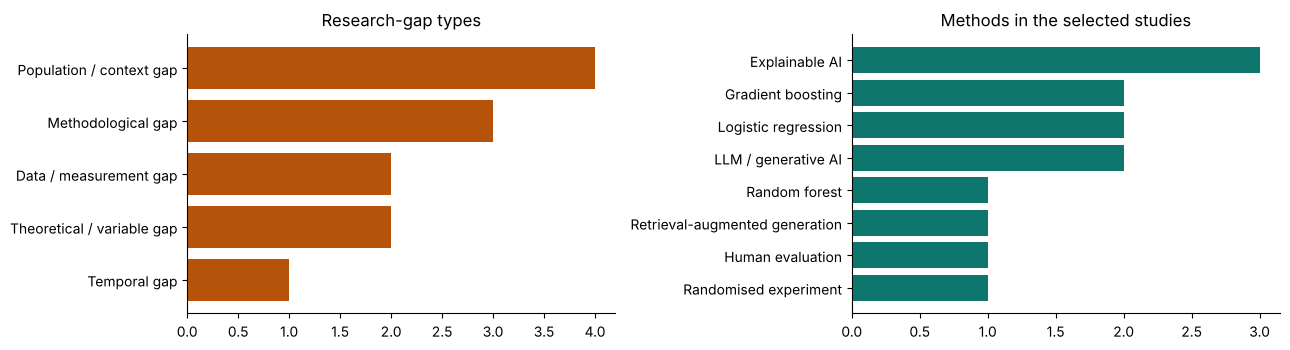

Prior studies leave several gaps. Population / context gap — (Krishnan et al., 2024), (Menon et al., 2025), (Rao et al., 2026) note that the experiment was conducted in a single bank, and the twelve-week horizon cannot capture long-term skill erosion. Methodological gap — (Fernandes & Gupta, 2025), (Menon et al., 2025), (Rao et al., 2026) note that quality was assessed by internal reviewers who may share organisational biases. Data / measurement gap — (Fernandes & Gupta, 2025) note that the benchmark is limited to English papers, and figures and tables were not parsed. Moreover, no study in this set applies difference-in-differences in the scholarly publishing context, which remains unexplored.


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
t = pd.Series(S["gaps"]["types"]).sort_values()
ax[0].barh(t.index, t.values, color="#B45309"); ax[0].set_title("Research-gap types")
mth = pd.Series(S["methodology"]["methods"]).sort_values().tail(8)
ax[1].barh(mth.index, mth.values, color="#0F766E"); ax[1].set_title("Methods in the selected studies")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print(S["gaps"]["draft"])

In [27]:
display(pd.DataFrame(S["methodology"]["table"]))
display(pd.DataFrame([{"X": r["iv"], "effect": r["sign"], "Y": r["dv"], "source": r["cite"]} for r in S["model"]["relations"]]))
for h in S["hypotheses"]: print(h["id"], h["text"], h["support"])
print()
for q in S["questions"]: print(q["id"], q["text"])

,Study,Design,Methods,Sample,Context
0,"(Rao et al., 2026)","Experimental, Quasi-experimental","Difference-in-differences, Randomised experiment, LLM / generative AI","412 analysts; 9,860 completed tasks","IT / technology firms, Banking & finance"
1,"(Fernandes & Gupta, 2025)",Design science / artefact,"LLM / generative AI, Retrieval-augmented generation","1,200 open-access papers",Scholarly publishing
2,"(Menon et al., 2025)",Secondary / archival data,"Logistic regression, Random forest, Gradient boosting","18,420 employees",IT / technology firms
3,"(Krishnan et al., 2024)",Secondary / archival data,"Logistic regression, Gradient boosting, Explainable AI","52,300 loan applications",Banking & finance
4,"(Demo, 2023)",Not classified,Explainable AI,—,Unspecified


,X,effect,Y,source
0,copilot,−,average task completion time,"(Rao et al., 2026)"
1,SecRAG,+,factual consistency,"(Fernandes & Gupta, 2025)"
2,commute distance and manager change frequency,+,voluntary employee attrition,"(Menon et al., 2025)"
3,months since last promotion,+,voluntary employee attrition,"(Menon et al., 2025)"
4,alternative data model,+,Gini coefficient,"(Krishnan et al., 2024)"


H1 There is a negative effect of copilot on average task completion time. (Rao et al., 2026)
H2 There is a positive effect of SecRAG on factual consistency. (Fernandes & Gupta, 2025)
H3 There is a positive effect of commute distance on voluntary employee attrition. (Menon et al., 2025)
H4 There is a positive effect of manager change frequency on voluntary employee attrition. (Menon et al., 2025)
H5 There is a positive effect of months since last promotion on voluntary employee attrition. (Menon et al., 2025)
H6 There is a positive effect of alternative data model on Gini coefficient. (Krishnan et al., 2024)
H7 The effect of copilot on average task completion time is stronger for junior analysts. (Rao et al., 2026)

RQ1 Does the effect of copilot on average task completion time hold in other sectors, institutions and countries beyond those studied by Rao et al., 2026?
RQ2 Does the effect of copilot on average task completion time remain when tested with a randomised or longitudinal desi

### B4. One-page cheatsheet per paper (PDF)

In [28]:
from authorshand.cheatsheet import cheatsheet_pdf
pdf = cheatsheet_pdf([a for a in S["articles"] if a["summary"]["fields"]["key_findings"]][:3], "apa")
Path("docs/sample_cheatsheets.pdf").write_bytes(pdf)
print("cheatsheet PDF:", len(pdf) // 1024, "KB, starts with", pdf[:5])

cheatsheet PDF: 15 KB, starts with b'%PDF-'


![cheatsheet](docs/report_img/cheatsheet_preview.png)

### B5. Rapid Journal Quality Check (demo uses two fictional journals)

In [29]:
from authorshand.journal_quality import JournalChecker, load_list
lst = load_list("demo_data/sample_quality_list.csv", "ABDC (sample)")
for j in ["Journal of Demo Analytics", "Rapid Multidisciplinary"]:
    r = JournalChecker(demo_mode=True, lists=[lst]).check(j)
    print(f"{r['name']}: {r['score']}/100 → {r['verdict']}")
    for f in r["red_flags"]: print("   🚩", f)

Journal of Demo Analytics (fictional): 100/100 → Looks reputable
International Journal of Rapid Multidisciplinary Publication (fictional): 0/100 → High risk — avoid unless verified
   🚩 Sudden output surge (> 3× the previous years) — a common paper-mill pattern.
   🚩 Charges an APC (US$180) but is not listed in DOAJ.
   🚩 Very high volume with very low citation impact.


### B6. Tool Hub — add-ins mapped to writing stages

In [30]:
from authorshand import tools_hub as hub
reg = pd.DataFrame(hub.REGISTRY)
display(reg.groupby(["category", "connection"]).size().unstack(fill_value=0))
print("Tools suggested for the Research-gap stage:", [t["name"] for t in hub.for_stage("Research gap")])
print("Pre-filled launch:", hub.launch_url(hub.get("connectedpapers"), "explainable credit scoring"))

connection,api,builtin,deeplink,exchange
category,,,,
Discovery,0,2,7,0
Journal quality,0,2,6,0
Journal selection,0,1,5,0
Literature mapping,0,1,1,3
Methods & analysis,0,0,4,0
Reading & AI analysis,0,1,3,0
Reference management,1,0,0,3
Research integrity,0,1,0,0
Writing,0,1,4,1


Tools suggested for the Research-gap stage: ['Citation Map (built-in)', 'Writing Studio (built-in)', 'Elicit', 'Connected Papers', 'Litmaps', 'Inciteful']
Pre-filled launch: https://www.connectedpapers.com/search?q=explainable+credit+scoring


### B7. Citation map (Litmaps-style)

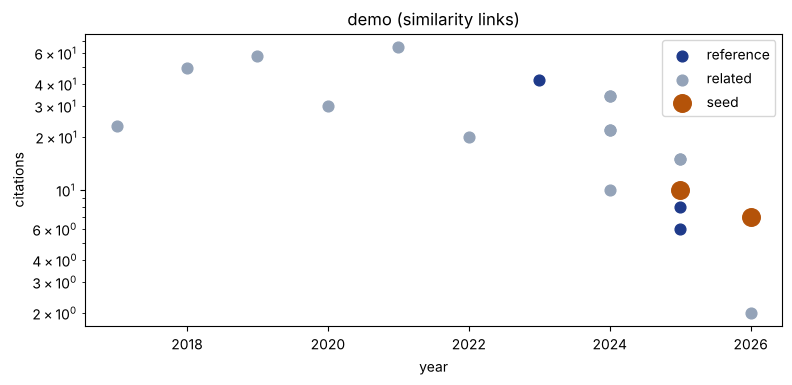

In [31]:
from authorshand.citation_map import build_map
m = build_map([a["paper"] for a in arts[:2]], demo_mode=True, per_seed=5)
nodes = pd.DataFrame(m["nodes"])
colors = {"seed": "#B45309", "reference": "#1E3A8A", "citing": "#0F766E", "related": "#94A3B8"}
plt.figure(figsize=(9, 3.8))
for k, g in nodes.groupby("kind"):
    plt.scatter(g["year"], g["citations"] + 1, s=160 if k == "seed" else 60, c=colors[k], label=k)
plt.yscale("log"); plt.xlabel("year"); plt.ylabel("citations"); plt.legend(); plt.title(m["mode"]); plt.show()

# Part C — Version 3: trust, review workflow and identity

Feedback on version 2 asked for: evidence you can trace, clear labels separating extracted evidence from AI-written text, corrections, a reproducible review workflow, honest evaluation on real papers, and privacy controls. This part demonstrates each.

### C1. Accounts: sign-up / sign-in with Gmail or ORCID iD (passwords stored only as salted PBKDF2 hashes)

In [32]:
from authorshand import auth
from authorshand.store import Workspace
import tempfile, os
wsc = Workspace(os.path.join(tempfile.mkdtemp(), "accounts.db"))
user, recovery = auth.sign_up(wsc, "Dr. R. Researcher", "researcher@gmail.com", "0000-0002-1825-0097", "research2026", "research2026")
print("account:", user["email"], "| one-time recovery code:", recovery)
print("sign in with ORCID iD →", auth.sign_in(wsc, "0000-0002-1825-0097", "research2026")["name"])
try:
    auth.sign_in(wsc, "researcher@gmail.com", "wrong-password")
except auth.AuthError as e:
    print("wrong password →", e)
row = wsc.db.execute("SELECT password_hash FROM users WHERE email=?", ("researcher@gmail.com",)).fetchone()
print("what is stored:", row[0][:24], "… (hash, never the password)")

account: researcher@gmail.com | one-time recovery code: 62AC-CF43-C90B-A44F
sign in with ORCID iD → Dr. R. Researcher
wrong password → Wrong password. Use “Forgot password?” with your recovery code if needed.
what is stored: 2291804569c9c5c85dbab4f7 … (hash, never the password)


*Continue with Google / Continue with ORCID* use OpenID Connect via Streamlit's `st.login` once the user registers a free client ID (Settings → Sign-in providers). Google Scholar has **no API** and forbids scraping, so its metrics come from SerpApi (user's own key), manual entry, or the user's Scholar export — always shown with the source and date.

### C2. Evidence tracing — every statement → passage, section, page, DOI and support strength

In [33]:
from authorshand import evidence as EV
from authorshand.writing import WritingStudio
p = demo._with_pdf_pages(demo.load_corpus()["papers"][0])
print("text used:", EV.text_source(p, p["text"]))
s3 = summarizer.summarize(p["text"], p["title"], pages=p["pages_text"])
pd.DataFrame(s3["evidence"])[["field", "strength", "support", "section", "page", "claim"]].head(6)

text used: Full text (PDF, 3 pages)


,field,strength,support,section,page,claim
0,tldr,strong,1.0,abstract,1,"Using HR records of 18,420 employees from three mid-sized IT firms, we compare logistic regression, random forest an..."
1,problem,strong,1.0,introduction,1,"However, most predictive attrition studies rely on the public IBM HR dataset, which is synthetic and small."
2,problem,strong,1.0,introduction,1,Little is known about how well attrition models generalise to real Indian workforce data.
3,objectives,strong,1.0,introduction,1,This study addresses both gaps.
4,objectives,strong,1.0,introduction,1,Our objective is to build an accurate and explainable early-warning model and to examine which organisational driver...
5,methodology,strong,1.0,methodology,1,"Three models were trained: logistic regression, random forest and XGBoost."


In [34]:
art = WritingStudio().profile_article(p, p["text"], s3)
draft = ("XGBoost outperformed the other models with an AUC of 0.89 (Menon et al., 2025). "
         "Attrition models are now used in every Indian bank.")
pd.DataFrame(EV.trace_statements(draft, [art]))[["statement", "label", "strength", "support", "page", "doi"]]

,statement,label,strength,support,page,doi
0,"XGBoost outperformed the other models with an AUC of 0.89 (Menon et al., 2025).",Extracted from the paper,strong,0.526,2,10.0000/demo.2025.001
1,Attrition models are now used in every Indian bank.,AI-generated wording,weak,0.211,1,10.0000/demo.2025.001


The second sentence is **not** in the source: it gets *weak* support and the label *AI-generated wording*, so the user knows to check it. Candidate research gaps are labelled *Candidate — verify*, never presented as findings.

### C3. Corrections and field-specific terms (the user stays in control)

In [35]:
ex = {"methods": ["Survey / questionnaire"], "table_sample": "412 analysts (corrected by the author)"}
fixed = WritingStudio().profile_article(dict(p, extraction=ex), p["text"])
custom = WritingStudio(lexicon={"methods": {"Early-warning analytics": ["early-warning"]}}).profile_article(
    demo.load_corpus()["papers"][3], demo.load_corpus()["papers"][3]["text"])
print("corrected methods:", fixed["methods"], "| sample:", fixed["table"]["Sample"])
print("custom term detected:", "Early-warning analytics" in custom["methods"],
      "| because of:", custom["method_sources"]["Early-warning analytics"]["sentence"][:90])

corrected methods: ['Survey / questionnaire'] | sample: 412 analysts (corrected by the author)
custom term detected: True | because of: This study builds an early-warning model for postgraduate management students using LMS ac


### C4. Reproducible systematic review — logged searches, duplicate reasons, screening, PRISMA 2020

In [36]:
from authorshand import review as RV
pid_r = wsc.create_project("researcher@gmail.com", "Review: explainable ML in HR")
log = RV.run_search(wsc, pid_r, ["OpenAlex", "Semantic Scholar", "arXiv"], "explainable machine learning", {}, 6, demo_mode=True)
display(pd.DataFrame(log))
recs = RV.records(wsc, pid_r)
RV.set_decision(wsc, recs[0]["id"], "include")
RV.set_decision(wsc, recs[1]["id"], "exclude", "Wrong study design")
display(RV.duplicate_log(wsc, pid_r).head())
counts = RV.prisma_counts(wsc, pid_r)
counts

,database,results,note
0,OpenAlex,3,demo corpus (offline)
1,Semantic Scholar,3,demo corpus (offline)
2,arXiv,3,demo corpus (offline)


,removed,found in,kept,reason
0,2 repeat hit(s),several searches,Predicting Voluntary Employee Attrition with Explainable Gradient Boosting: Evidence from Indian IT Services,identical DOI/title in another search
1,2 repeat hit(s),several searches,Learning Analytics for Early Identification of At-Risk Postgraduate Management Students,identical DOI/title in another search
2,2 repeat hit(s),several searches,Explainable Credit Scoring for Thin-File Borrowers Using Alternative Data,identical DOI/title in another search


{'identified': 9,
 'by_database': {'OpenAlex': 3, 'Semantic Scholar': 3, 'arXiv': 3},
 'duplicates_removed': 6,
 'screened': 3,
 'excluded': 1,
 'maybe': 0,
 'included': 1,
 'unscreened': 1,
 'exclusion_reasons': {'Wrong study design': 1}}

In [37]:
print(RV.methods_paragraph(wsc, pid_r, {"review_type": "Systematic review", "question": "How is explainable ML used in HR decisions?"}))

A systematic review was conducted to answer the question: “How is explainable ML used in HR decisions?”. OpenAlex, Semantic Scholar, arXiv were searched on 29 October 2026 using the search string(s) “explainable machine learning”. The searches identified 9 records; after removing 6 duplicates, 3 records were screened on title and abstract against pre-defined criteria (inclusion: [criteria]; exclusion: [criteria]). 1 records were excluded — Wrong study design (n = 1) — and 1 studies were included in the synthesis. Screening decisions and reasons were recorded in Author's Hand and are available as a supplementary file.


### C5. Google Scholar metrics (parsed exactly as returned by the SerpApi `google_scholar_author` engine)

,all,since,since_year
citations,512,431,2021
h_index,11,10,2021
i10_index,11,9,2021


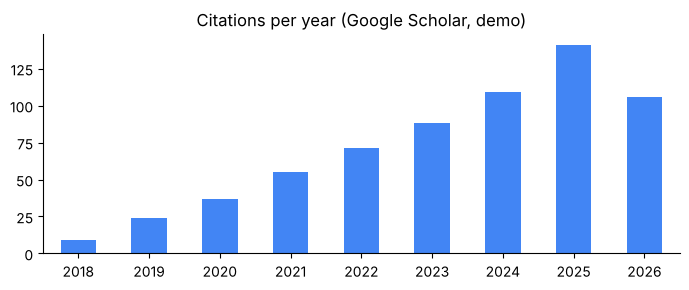

In [38]:
from authorshand import gscholar as GS
snap = GS.DEMO_SNAPSHOT        # fictional numbers for the offline demo
display(pd.DataFrame(snap["metrics"]).T)
g = pd.Series(snap["graph"]).sort_index()
ax = g.plot.bar(figsize=(7, 3), color="#4285F4", rot=0, title="Citations per year (Google Scholar, demo)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 11. Testing and evaluation

| Test | What it measures |
|---|---|
| **Unit tests** (`pytest`, 33 tests) | citations in 9 styles, workspace, Writing Studio, cheatsheet, journal check, add-ins, ORCID checksum, ResearchGate BibTeX/RIS parsing, de-duplication, ORCID/OpenAlex/arXiv response parsing (recorded formats), sections, schema, RAG citations, agent routing, LLM path with a mocked model |
| **ROUGE-1/2/L** vs hand-written reference summaries | content overlap of the executive summary |
| **LEAD-3 baseline** | the standard summarisation baseline (first three sentences) |
| **Field coverage** | share of the 9 structured fields filled |
| **Retrieval Hit@3, MRR, answer accuracy** | RAG quality on 10 QA pairs |
| **Hallucination probe** | inject a false claim; does grounding flag it? |
| **Real-paper protocol** | abstract removed, body summarised, compared with the authors' abstract vs LEAD-3; failure cases listed |
| **Human ratings** | in the app, users rate accuracy/usefulness and note errors per paper (Evaluation → Human ratings) |

> ⚠️ **Limitation — read first.** The ROUGE, retrieval and probe numbers below come from a **small synthetic corpus written for testing**. They show the pipeline works; they are **not** evidence of quality on real literature. The real-paper protocol (below) is the method to use on genuine PDFs, and the app runs it on the user's own library.

In [39]:
import subprocess
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider", "tests"], capture_output=True, text=True)
print(out.stdout[-600:])

.................................                                        [100%]
33 passed in 2.80s



In [40]:
summ_eval = evaluation.evaluate_summaries(summarizer, corpus["papers"])
lead3 = evaluation.evaluate_baseline_lead3(corpus["papers"])
display(summ_eval)
display(lead3)

,paper,rouge1,rouge2,rougeL,faithfulness,field_coverage,exec_words,compression,latency_s
0,Predicting Voluntary Employee Attrition with,0.4783,0.2281,0.3826,1.0,1.0,139.0,0.5110,0.26
1,Generative AI Copilots and Analyst Productivi,0.5306,0.2268,0.4082,1.0,1.0,112.0,0.4710,0.02
2,Retrieval-Augmented Generation for Faithful S,0.5073,0.2167,0.3805,1.0,1.0,121.0,0.5370,0.02
3,Learning Analytics for Early Identification o,0.5051,0.2449,0.2525,1.0,1.0,120.0,0.6240,0.02
4,Explainable Credit Scoring for Thin-File Borr,0.5069,0.2140,0.2857,1.0,1.0,129.0,0.6440,0.03
5,MEAN,0.5056,0.2261,0.3419,1.0,1.0,124.2,0.5574,0.07


,paper,rouge1,rouge2,rougeL
0,Predicting Voluntary Employee Attrition with,0.4225,0.2571,0.1972
1,Generative AI Copilots and Analyst Productivi,0.4122,0.2171,0.2901
2,Retrieval-Augmented Generation for Faithful S,0.5255,0.3259,0.4672
3,Learning Analytics for Early Identification o,0.4567,0.3040,0.2835
4,Explainable Credit Scoring for Thin-File Borr,0.3453,0.2044,0.2014
5,MEAN,0.4324,0.2617,0.2879


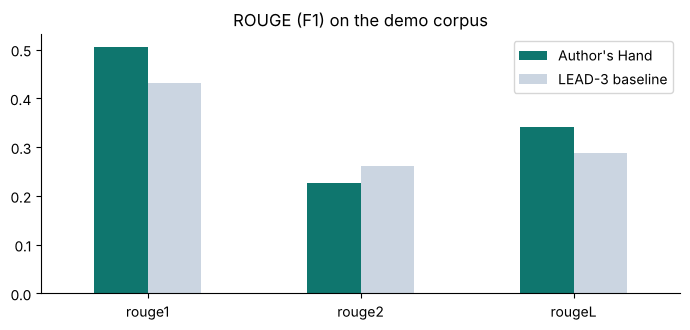

,Author's Hand,LEAD-3 baseline
rouge1,0.5056,0.4324
rouge2,0.2261,0.2617
rougeL,0.3419,0.2879


In [41]:
mean_s, mean_b = summ_eval.iloc[-1], lead3.iloc[-1]
comp = pd.DataFrame({"Author's Hand": mean_s[["rouge1", "rouge2", "rougeL"]].astype(float),
                     "LEAD-3 baseline": mean_b[["rouge1", "rouge2", "rougeL"]].astype(float)})
ax = comp.plot.bar(figsize=(7, 3.4), color=["#0f766e", "#cbd5e1"], rot=0, title="ROUGE (F1) on the demo corpus")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
comp

In [42]:
ret = evaluation.evaluate_retrieval(index, corpus["qa"], k=3)
print({k: v for k, v in ret.items() if k != "details"})
ret["details"]

{'hit@3': 1.0, 'mrr': 0.867, 'answer_accuracy': 0.9}


,question,hit@k,rank,answer_correct
0,What AUC did XGBoost achieve for attrition prediction?,True,1,True
1,How many analysts took part in the copilot experiment?,True,1,True
2,By how much did the copilot reduce task completion time?,True,1,True
3,What share of injected false claims did the verification step remove?,True,1,True
4,What F1 score did the at-risk student model reach by week five?,True,1,True
5,How much did model-triggered mentoring reduce course failure?,True,3,True
6,What Gini coefficient did the alternative data model achieve?,True,1,True
7,Which alternative data features were most important for credit scoring?,True,3,False
8,What was the strongest driver of employee attrition according to SHAP?,True,1,True
9,How many papers were in the SecRAG benchmark?,True,1,True


In [43]:
probe = evaluation.hallucination_probe(summarizer, corpus["papers"][1]["text"], corpus["papers"][1]["title"],
                                       "The copilot doubled revenue in European branches.")
probe

{'injected_support': 0.032, 'genuine_mean_support': 1.0, 'flagged': True}

In [44]:
# Robustness: unstructured input (no headings) and a very short abstract-only input
plain = " ".join(corpus["papers"][3]["text"].split())       # headings flattened away
short = "Abstract: We test a chatbot for HR queries with 2,000 employees and find a 40 percent drop in tickets."
for name, t in [("flattened text", plain), ("abstract only", short)]:
    x = summarizer.summarize(t, title=name)
    print(f"{name:15s} sections={x['sections_found']}  fields filled={evaluation.field_coverage(x):.0%}  tldr={x['fields']['tldr'][:80]}")

flattened text  sections=['body']  fields filled=100%  tldr=Mentor interventions triggered by the model reduced course failure by 19 percent
abstract only   sections=['abstract']  fields filled=22%  tldr=We test a chatbot for HR queries with 2,000 employees and find a 40 percent drop


### Real-paper protocol and failure cases
Run on any full-text papers (here the demo PDFs, to show the output format). In the app: **Evaluation → Your real papers**.

In [45]:
own = [demo._with_pdf_pages(x) for x in demo.load_corpus()["papers"][:5]]
real = evaluation.evaluate_own_papers(summarizer, [{"title": x["title"], "text": x["text"]} for x in own])
display(real["table"])
print("failure cases:")
real["failures"]

,paper,rouge1,rouge2,rougeL,lead3_rouge1,beats_lead3,fields_missing,weak_claims,faithfulness
0,Predicting Voluntary Employee Attrition with Expla,0.4595,0.2455,0.3964,0.2013,True,1,0,1.0
1,Generative AI Copilots and Analyst Productivity in,0.4724,0.1624,0.2814,0.1857,True,1,0,1.0
2,Retrieval-Augmented Generation for Faithful Summar,0.4277,0.2293,0.2013,0.2063,True,1,0,1.0
3,Learning Analytics for Early Identification of At-,0.4222,0.1573,0.2222,0.2256,True,1,0,1.0
4,Explainable Credit Scoring for Thin-File Borrowers,0.5135,0.1636,0.2703,0.2174,True,1,0,1.0


failure cases:


,paper,problem
0,Predicting Voluntary Employee Attrition with Explainable Gra,no content found for: future_work
1,Generative AI Copilots and Analyst Productivity in Retail Ba,no content found for: future_work
2,Retrieval-Augmented Generation for Faithful Summarisation of,no content found for: future_work
3,Learning Analytics for Early Identification of At-Risk Postg,no content found for: future_work
4,Explainable Credit Scoring for Thin-File Borrowers Using Alt,no content found for: future_work


## 12. Final results

In [46]:
results = pd.DataFrame([
    ("Summary ROUGE-1 / ROUGE-L (mean)", f"{mean_s.rouge1:.3f} / {mean_s.rougeL:.3f}", f"LEAD-3: {mean_b.rouge1:.3f} / {mean_b.rougeL:.3f}"),
    ("Summary ROUGE-2 (mean)", f"{mean_s.rouge2:.3f}", f"LEAD-3: {mean_b.rouge2:.3f}"),
    ("Structured-field coverage", f"{mean_s.field_coverage:.0%}", "9 fields per paper"),
    ("Retrieval Hit@3 / MRR", f"{ret['hit@3']:.0%} / {ret['mrr']:.2f}", "10 QA pairs"),
    ("QA answer accuracy", f"{ret['answer_accuracy']:.0%}", "answer contains the gold fact"),
    ("Hallucination probe", "flagged" if probe["flagged"] else "missed", f"support {probe['injected_support']} vs {probe['genuine_mean_support']}"),
    ("Mean summarisation latency (local engine)", f"{mean_s.latency_s:.2f} s", "CPU, no GPU"),
    ("Unit tests", out.stdout.strip().splitlines()[-1], "pytest"),
], columns=["Metric", "Result", "Note"])
results

,Metric,Result,Note
0,Summary ROUGE-1 / ROUGE-L (mean),0.506 / 0.342,LEAD-3: 0.432 / 0.288
1,Summary ROUGE-2 (mean),0.226,LEAD-3: 0.262
2,Structured-field coverage,100%,9 fields per paper
3,Retrieval Hit@3 / MRR,100% / 0.87,10 QA pairs
4,QA answer accuracy,90%,answer contains the gold fact
5,Hallucination probe,flagged,support 0.032 vs 1.0
6,Mean summarisation latency (local engine),0.07 s,"CPU, no GPU"
7,Unit tests,33 passed in 2.80s,pytest


**Interpretation.**
* Author's Hand beats the LEAD-3 baseline on ROUGE-1 and ROUGE-L while also filling all nine structured fields — something LEAD-3 cannot do. LEAD-3 stays slightly ahead on ROUGE-2 because the synthetic abstracts are already summary-like.
* In local mode faithfulness is 1.0 **by construction** (sentences are extracted). Its value lies in LLM mode, where the probe shows the grounding check separates invented claims (support ≈ 0.03) from genuine ones.
* Retrieval found the right evidence for all 10 questions (Hit@3 = 100%). The one wrong answer ("which features…") had the evidence retrieved, but the extractive answerer picked a neighbouring sentence — an LLM answerer or a re-ranker fixes this class of error.
* **Caveat (important):** the demo corpus is small and synthetic, so these numbers do not measure real-world quality. Failure cases above (missing fields, weakly supported claims, below-baseline papers) are reported rather than hidden. Next step: run the real-paper protocol on 30+ genuine PDFs from the user's field, with human ratings, and on public benchmarks (arXiv/PubMed summarisation, SciFact).

## 13. Live mode (internet + any LLM)

Set `LIVE = True`, add a contact e-mail (OpenAlex/Crossref "polite pool") and optionally an LLM key, e.g.
`export GROQ_API_KEY=...` (free tier) · `export ANTHROPIC_API_KEY=...` · or run `ollama serve` locally.

In [47]:
LIVE = False          # ← switch to True on a machine with internet access
MY_ORCID = "0000-0002-1825-0097"   # replace with your own ORCID iD

if LIVE:
    settings = Settings(contact_email="you@institution.edu")
    live = ResearchAgent(llm=LLM("auto"), settings=settings, demo_mode=False)
    r = live.run(f"Analyse my research profile, ORCID {MY_ORCID}")
    print(r.output.get("metrics"), r.output.get("health", {}).get("score"))
    r = live.run("Summarise arXiv:2005.11401")          # the original RAG paper
    print(exporters.summary_markdown(r.output["summary"])[:1500])
    r = live.run("Literature review on retrieval augmented generation for scientific summarisation with 5 papers")
    display(r.output["review"]["matrix"])
else:
    print("Live mode is off — all results above come from the offline demo corpus.")

Live mode is off — all results above come from the offline demo corpus.


## Conclusion
Author's Hand delivers an **autonomous, identity-anchored research agent**: from one ORCID iD (plus a ResearchGate link/export) it builds a unified research profile, and from a plain-English goal it plans and runs the full workflow — search, read, summarise, verify, personalise and synthesise — with an auditable trace and evidence for every claim. It runs free and offline, scales up with any LLM, and is deployed as a Streamlit app (`app.py`) and a REST API (`api.py`).

**Version 3 added:** accounts (Gmail / ORCID iD, Google & ORCID OpenID Connect), evidence tracing to page and DOI, extracted/AI/candidate labels, corrections and field terms, systematic review with PRISMA, Google Scholar metrics, privacy controls, backup/restore/delete and a Windows desktop app.

**Future improvements:** table/figure parsing, multilingual papers, LLM-judge (entailment) faithfulness, citation-graph expansion (snowballing), ORCID member-API write-back of verified works, and evaluation on public benchmarks.